### Instant Ramen Rating Prediction System
System predicting the star rating of instant ramen based on its traits like:
- country of origin;
- brand;
- flavours (for example: chicken, spicy);
- style of packaging.

Model is trained on data from **Kaggle** named [Ramen Ratings](https://www.kaggle.com/datasets/residentmario/ramen-ratings). The core of the system is built using a **Random Forest Regressor**. Model performance is evaluated using **Mean Absolute Error**. Project is inspired by an instagram reel by @pycode.hubb.

#### Loading the data and cleaning it

In [29]:
import pandas as pd

df = pd.read_csv("ramen-ratings.csv")
df = df[df.Stars!="Unrated"]
df["Stars"] = df["Stars"].astype(float)
df = df.drop(columns=["Top Ten", "Review #"])

First and foremost the data is imported and cleaned. The columns labeled as **"Top Ten"** and **"Review #"** were dropped entirely as they don't serve any purpose (one is an unnecessary ranking, the other just a numer of a review). Any unrated ramen was also not included in dataset.

In [30]:
df.head()

,Brand,Variety,Style,Country,Stars
0,New Touch,T's Restaurant Tantanmen,Cup,Japan,3.75
1,Just Way,Noodles Spicy Hot Sesame Spicy Hot Sesame Guan...,Pack,Taiwan,1.00
2,Nissin,Cup Noodles Chicken Vegetable,Cup,USA,2.25
3,Wei Lih,GGE Ramen Snack Tomato Flavor,Pack,Taiwan,2.75
4,Ching's Secret,Singapore Curry,Pack,India,3.75


#### Data Analysis using diagrams
Before going into splitting the data into test and training parts, I've decided  to analyse the data to gain better understanding of it. Knowledge about what to expect is important in the final analysis of the model.

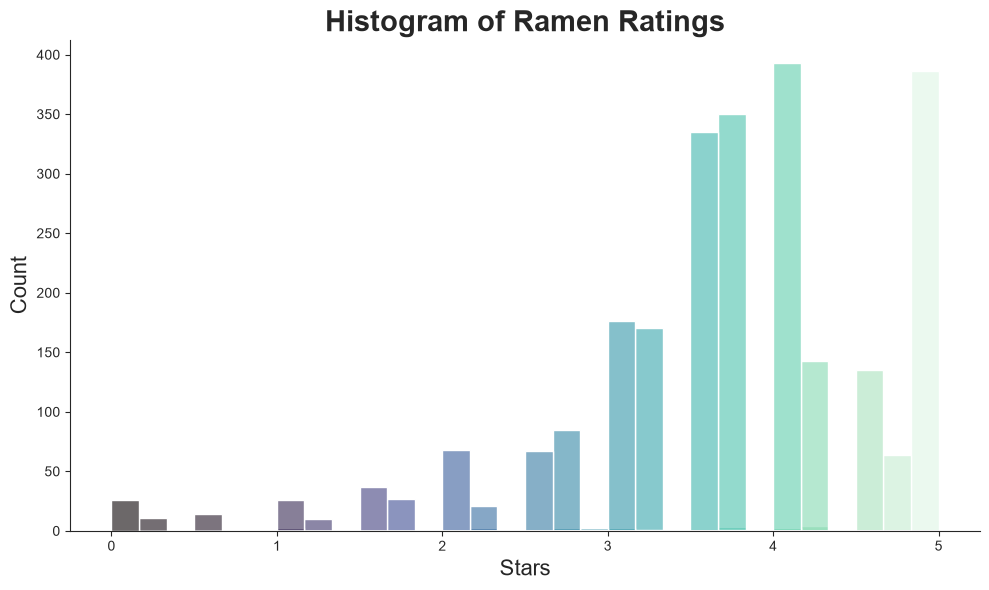

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))

sns.set_style("ticks")
sns.histplot(data=df, x="Stars", bins=30, hue="Stars", palette="mako", legend=False,alpha=0.6, kde=True)
sns.despine()

plt.title("Histogram of Ramen Ratings", fontsize=21, fontweight="bold")
plt.xlabel("Stars", fontsize=16)
plt.ylabel("Count", fontsize=16)

plt.tight_layout()
plt.show()

This histogram shows how varied the ratings of ramens are. You can clearly see that most of the reviewers weren't exactly strict about their ratings - most of them are in **between 3 and 4,5**. There are not many low marks, that might suggest that any ramen subjected to the test shouldn't gain especially low score.

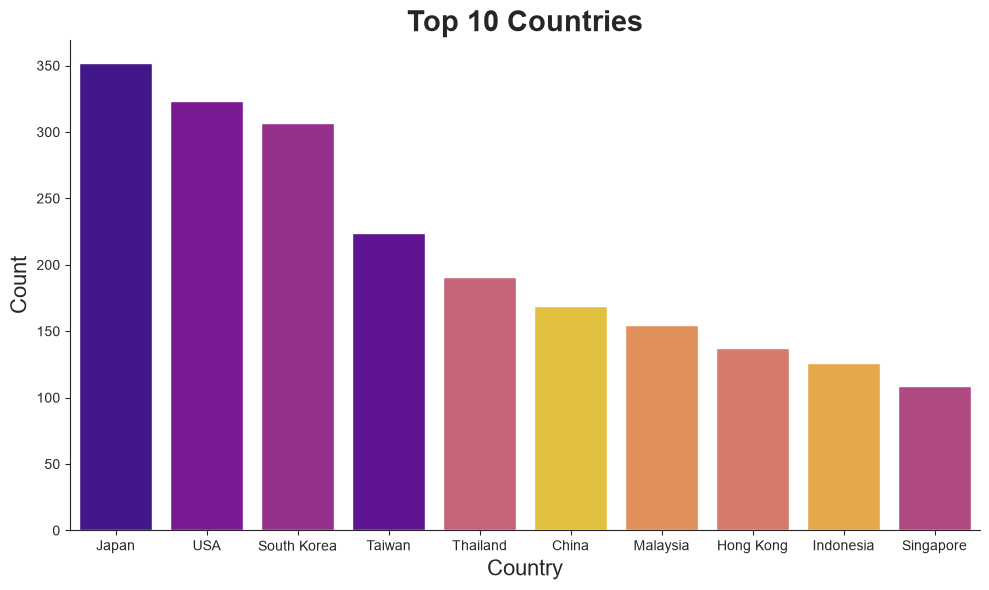

In [36]:
top_10 = df["Country"].value_counts().head(10).index
df_top_countries = df[df["Country"].isin(top_10)]

plt.figure(figsize=(10,6))
sns.set_style("ticks")
sns.countplot(data=df_top_countries, x="Country", hue="Country", palette="plasma", legend=False, order=top_10)
sns.despine()

plt.title("Top 10 Countries", fontsize=21, fontweight="bold")
plt.xlabel("Country", fontsize=16)
plt.ylabel("Count", fontsize=16)

plt.tight_layout()
plt.show()

Most of the records in the file are from Japan, second best is USA and South Korea.

#### Creating flavour types from Variety column

In [40]:
df["is_spicy"] = df["Variety"].str.contains("spicy", case=False).astype(int)
df["is_chicken"] = df["Variety"].str.contains("chicken", case=False).astype(int)
df["is_creamy"] = df["Variety"].str.contains("creamy", case=False).astype(int)
df["is_tomato"] = df["Variety"].str.contains("tomato", case=False).astype(int)
df["is_shrimp"] = df["Variety"].str.contains("shrimp", case=False).astype(int)
df["is_beef"] = df["Variety"].str.contains("beef", case=False).astype(int)

df = df.drop(columns=["Variety"])

After looking through the table, I've written up words that came into my attention as good and frequent descriptions of taste on ramen packaging.

This code creates new columns assesing whether the ramen is for example spicy, creamy or uses beef or chicken. Then the original variety column is dropped.

#### Encoding data for future model

In [41]:
x = df[["Brand", "Style", "Country", "is_creamy", "is_spicy", "is_chicken", "is_tomato", "is_shrimp", "is_beef"]]
y = df["Stars"]

x.join(y).head(3)

x = pd.get_dummies(x, columns=["Brand", "Style", "Country"], dtype=int)

Data is separated as x and y, where x is the data we provide for the model (features) and y is the target variable. Then data that is not already numeric is made into 0 and 1 with **One Hot Encoding (pd.get_dummies())** since
Machine Learning algorithims require **numerical input**.

#### Splitting data into test data and training data

In [42]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(random_state=42)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

To evaluate the model fairly on unseen examples, the dataset is split into an **80% training set and a 20% testing set**. Right after that, the **Random Forest** algorithm is put to work and learns the patterns from the training data.

#### Mean Absolute Error

In [43]:
from sklearn.metrics import mean_absolute_error
prediction = model.predict(x_test)
mae = mean_absolute_error(y_test, prediction)

print(f"Mean Absolute Error: {round(mae, 2)}")

Mean Absolute Error: 0.71


To see how well the algorithm performs, I calculated the **Mean Absolute Error** (MAE). This metric clearly shows how many stars, on average, the model's prediction is off from the actual ramen rating.

### Testing phase - new ramen put though the model

In [44]:
newRamen = pd.DataFrame({
    "Brand": ["Amino", "Samyang Foods"],
    "Style": ["Pack", "Pack"],
    "Country": ["Poland", "South Korea"],
    "is_spicy": [0, 1],
    "is_chicken": [0, 0],
    "is_creamy": [1, 1],
    "is_tomato": [1, 0],
    "is_shrimp": [0, 0],
    "is_beef": [0, 1]
})

newRamen = pd.get_dummies(newRamen, columns=["Brand", "Style", "Country"], dtype=int)
newRamen = newRamen.reindex(columns=x.columns, fill_value=0)
stars = model.predict(newRamen)
print("Predicted amount of stars Amino soup:", round(stars[0], 2))
print("Predicted amount of stars Samyang Foods soup:", round(stars[1], 2))

Predicted amount of stars Amino soup: 4.82
Predicted amount of stars Samyang Foods soup: 4.47


To test the performance of the trained model I've prepared two new ramens - Amino and Samyang with different flavour profiles. The data was transformed with One Hot Encoding and reindexed to match model's training structue.

The model generated different ratings for both soups which proves that it is reacting to features.

The rating it has predicted align perfectly with data analysis at the beginning - ratings have the tendency to be very positive.

### What traits define the perfect ramen? - Feature Importance

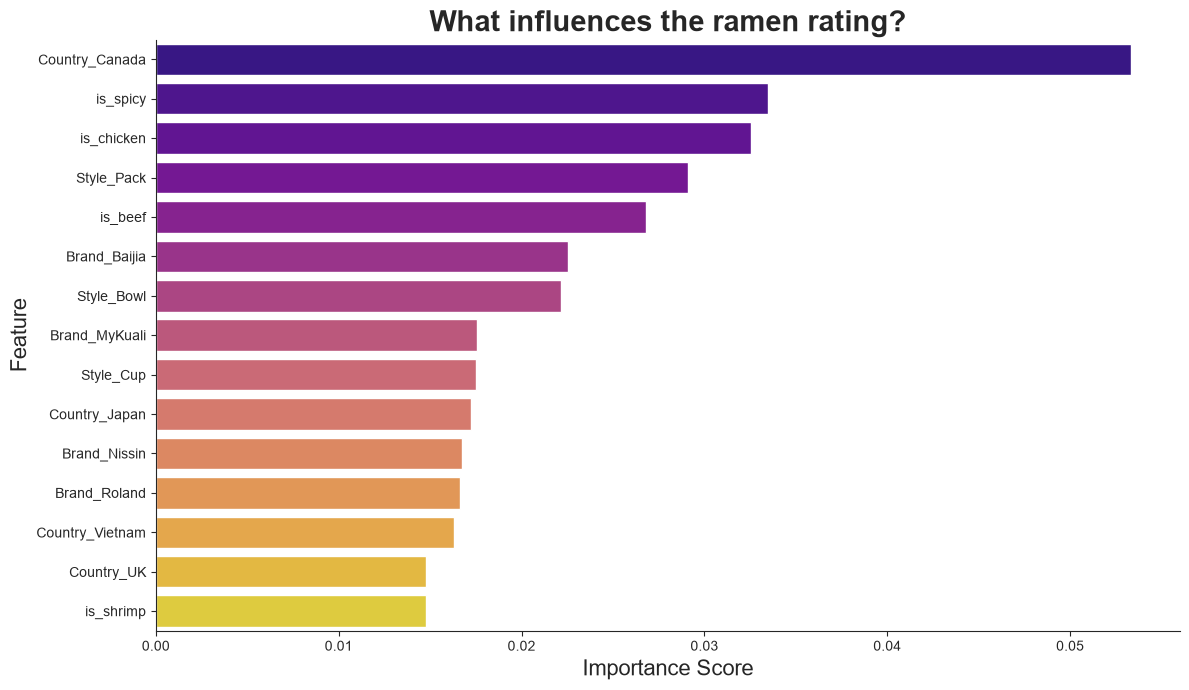

In [53]:
importances = model.feature_importances_

feature_names = x.columns
df_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances,
})

df_importance = df_importance.sort_values(by="Importance", ascending=False).head(15)

plt.figure(figsize=(12,7))
sns.set_style("ticks")

ax = sns.barplot(data=df_importance, x="Importance", y="Feature", hue="Feature", palette="plasma", legend=False)
ax.tick_params(axis="y", labelleft=True)
sns.despine()

plt.title("What influences the ramen rating?", fontsize=21, fontweight="bold")
plt.xlabel("Importance Score", fontsize=16)
plt.ylabel("Feature", fontsize=16)

plt.tight_layout()
plt.show()


Interestingly, even though Canada didn't make the top 10 most reviewed countries, originating from Canada turned out to be the strongest predictor in the entire model. Right after that, the biggest role in determining the final rating is played by specific extracted flavors: spiciness and chicken.